In [46]:
from sklearn import svm, metrics
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from PIL import Image, ImageOps

In [47]:
# 데이터 가져오기 
train_csv = pd.read_csv('data/train.csv', header=None)
# train_csv

test_csv = pd.read_csv('data/t10k.csv', header=None)
# test_csv

In [48]:
# 픽셀의 정규화 : 0 ~ 255 숫자를 0-1 사이의 숫자로 정규화 작업
def test(x):
    output = []
    for i in x:
        output.append(float(i)/256) # 256color 로 변환 
    return output



In [49]:
# train_csv[0] # 세로로 정보를 가져옴 
# train_csv.iloc[0] 
# train.head()

# 데이터 0-255 데이터 있음 / 0000 255 234 47 0 0 0 0 이런식으로 들어가 있다고 할 경우 글자 간격을 표준화시켜야함 
train_csv.iloc[0,1:].values # 1번을 제외하고 값을 가져옴 
train_cas_data = list(map(test, train_csv.iloc[:,1:].values))
train_cas_data


[[0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,

In [50]:
# train_csv.iloc[:,1:].values
train_cas_data = list(map(test, train_csv.iloc[:,1:].values))
test_csv_data = list(map(test, test_csv.iloc[:,1:].values))

In [51]:
# 정답 label 작업 
train_csv_label = train_csv[0].values  
train_csv_label
test_csv_label = test_csv[0].values
test_csv_label

array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6,
       6, 5, 4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2,
       3, 5, 1, 2, 4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5, 7, 8, 9, 3, 7, 4,
       6, 4, 3, 0, 7, 0, 2, 9, 1, 7, 3, 2, 9, 7, 7, 6, 2, 7, 8, 4, 7, 3,
       6, 1, 3, 6, 9, 3, 1, 4, 1, 7, 6, 9, 6, 0, 5, 4, 9, 9, 2, 1, 9, 4,
       8, 7, 3, 9, 7, 4, 4, 4, 9, 2, 5, 4, 7, 6, 7, 9, 0, 5, 8, 5, 6, 6,
       5, 7, 8, 1, 0, 1, 6, 4, 6, 7, 3, 1, 7, 1, 8, 2, 0, 2, 9, 9, 5, 5,
       1, 5, 6, 0, 3, 4, 4, 6, 5, 4, 6, 5, 4, 5, 1, 4, 4, 7, 2, 3, 2, 7,
       1, 8, 1, 8, 1, 8, 5, 0, 8, 9, 2, 5, 0, 1, 1, 1, 0, 9, 0, 3, 1, 6,
       4, 2, 3, 6, 1, 1, 1, 3, 9, 5, 2, 9, 4, 5, 9, 3, 9, 0, 3, 6, 5, 5,
       7, 2, 2, 7, 1, 2, 8, 4, 1, 7, 3, 3, 8, 8, 7, 9, 2, 2, 4, 1, 5, 9,
       8, 7, 2, 3, 0, 4, 4, 2, 4, 1, 9, 5, 7, 7, 2, 8, 2, 6, 8, 5, 7, 7,
       9, 1, 8, 1, 8, 0, 3, 0, 1, 9, 9, 4, 1, 8, 2, 1, 2, 9, 7, 5, 9, 2,
       6, 4, 1, 5, 8, 2, 9, 2, 0, 4, 0, 0, 2, 8, 4,

In [52]:
# 데이터 학습 
clf = svm.SVC() # 다른 알고리즘을 사용해도 됨
clf.fit(train_cas_data, train_csv_label)

# 데이터 예측 
result = clf.predict(test_csv_data)

# 정답률
# score = metrics.accuracy_score(test_csv_label,result)
score = clf.score(test_csv_data, test_csv_label)
print('정답률 :', score)

정답률 : 0.8842315369261478


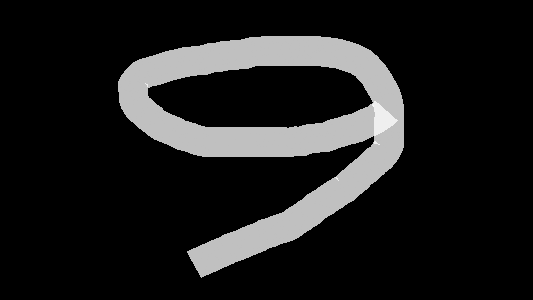

In [53]:
# 이미지 열기, 흑백으로 변환 
img = Image.open('data/a9_1.png').convert("L")
img

# 색상 반전 
img = ImageOps.invert(img)
img


In [54]:
# 숫자가 있는 영역만 추출
bbox = img.getbbox()
img = img.crop(bbox)
img

# 비율 축소 (20px*20px)
img.thumbnail((20,20), Image.Resampling.LANCZOS)
img

# 배경사이즈 28*28 로 변환
new_img = Image.new('L', (28, 28), 0)
new_img

# 배경사이즈 숫자를 가운데 붙여넣기
x = (28-img.width)//2 
y = (28-img.height)//2 
new_img.paste(img,(x,y))
new_img


In [55]:
# 예측용 데이터 
img_data = np.array(new_img, dtype=np.float32)
# img_data
flat_img_data = img_data.reshape(1,784)/256.0 
flat_img_data


array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.  

In [56]:
new_img.resize((280,280)).show()


In [57]:
# 데이터 예측 - 2차원 형태여야 예측이 됨 
result = clf.predict(flat_img_data)
print('예측번호 :', result)

예측번호 : [4]


In [58]:
# input = "0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 3 18 18 18 126 136 175 26 166 255 247 127 0 0 0 0 0 0 0 0 0 0 0 0 30 36 94 154 170 253 253 253 253 253 225 172 253 242 195 64 0 0 0 0 0 0 0 0 0 0 0 49 238 253 253 253 253 253 253 253 253 251 93 82 82 56 39 0 0 0 0 0 0 0 0 0 0 0 0 18 219 253 253 253 253 253 198 182 247 241 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 80 156 107 253 253 205 11 0 43 154 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 14 1 154 253 90 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 139 253 190 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 11 190 253 70 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 35 241 225 160 108 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 81 240 253 253 119 25 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 45 186 253 253 150 27 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 16 93 252 253 187 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 249 253 249 64 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 46 130 183 253 253 207 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 39 148 229 253 253 253 250 182 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 24 114 221 253 253 253 253 201 78 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 23 66 213 253 253 253 253 198 81 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 18 171 219 253 253 253 253 195 80 9 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 55 172 226 253 253 253 253 244 133 11 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 136 253 253 253 212 135 132 16 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0"
# input = input.split(' ')

# for i in range(len(input)):
#     print('{:3}'.format(input[i]), end='')
#     if i%28 == 0:
#         print()


In [59]:
# # 28x28 손글씨 이미지 흑백처리해서 255color 코드로 변경 
# input = input.split(' ')
# for i in range(len(input)):
#     print('{:3}'.format(input[i]), end='')
#     if i%28 == 0:
#         print()




In [60]:
df = pd.

SyntaxError: invalid syntax (261655203.py, line 1)